# Aşama 3–4: Unbinned likelihood ve anlamlılık

Aşama 2'deki sayımın iki zayıflığı vardı:
1. Dairenin içindeki her olayı **eşit** saydı: kaynağın dibindeki 0.2° belirsizlikli bir olayla kenardaki 3° belirsizlikli olay aynı ağırlıktaydı.
2. Dairenin dışındaki olayları **tamamen** yok saydı.

Likelihood her olaya kendi kanıt gücü kadar ağırlık veriyor:

$$\mathcal{L}(n_s) = \prod_{i=1}^{N}\left[\frac{n_s}{N}S_i + \left(1-\frac{n_s}{N}\right)B_i\right]$$

- $S_i$: olay kaynaktan gelseydi bu konumda olma olasılık yoğunluğu (kaynağa yakın ve kesinse büyük)
- $B_i$: olay arka plandan gelseydi bu konumda olma olasılık yoğunluğu (o Dec'teki kalabalık)
- $n_s$: verideki kaynak kaynaklı olay sayısı; **veriyi en iyi açıklayan değeri arıyoruz**

Ortak fonksiyonlar `src/icecube_ps.py` dosyasında; notebook'lar onu kullanıyor.

In [1]:
import sys; sys.path.append('../src')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
import icecube_ps as ps

RESULTS = Path('../results'); RESULTS.mkdir(exist_ok=True)
ev = ps.veri_yukle('../data')       # ilk seferde yavaş, sonra önbellekten hızlı
print(f"Toplam olay: {len(ev):,}")

Toplam olay: 1,134,450


## 1. Arka plan yoğunluğu $B_i$

Aşama 1'deki sin(Dec) histogramını bir olasılık yoğunluğuna çeviriyoruz. Histogram pürüzlü olduğu için üzerine yumuşak bir eğri (spline) oturtuyoruz; yoksa istatistiksel dalgalanmaları "gerçek yapı" sanırız.

$$B(\delta) = \frac{P(\sin\delta)}{2\pi}$$

Grafikte −5° civarındaki sıçramayı eğrinin yakalaması önemli: Aşama 2'de NGC 1068'in beklenen değerini kaydıran şey buydu.

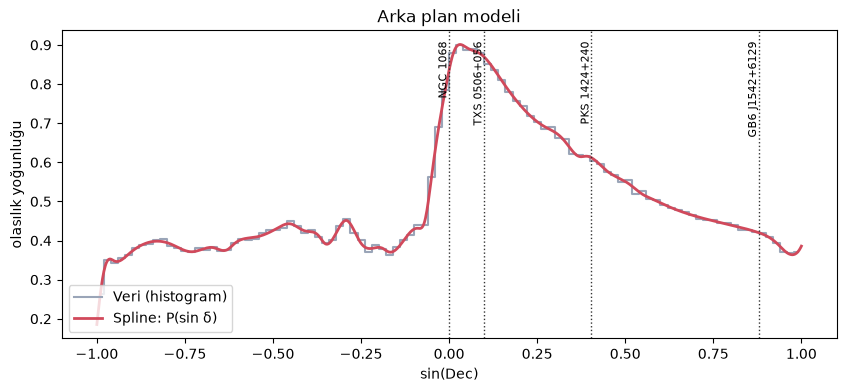

In [2]:
B = ps.ArkaPlan(ev['dec'].values)

x = np.linspace(-1, 1, 1000)
fig, ax = plt.subplots(figsize=(10, 4))
ax.step(B.merkez, B.yogunluk, where='mid', color='#9aa5b8', label='Veri (histogram)')
ax.plot(x, B.P(x), color='#d1495b', lw=2, label='Spline: P(sin δ)')
for ad, (ra_k, dec_k) in ps.KAYNAKLAR.items():
    ax.axvline(np.sin(np.radians(dec_k)), color='#333', ls=':', lw=1)
    ax.text(np.sin(np.radians(dec_k)), ax.get_ylim()[1] * 0.97, ad, rotation=90,
            va='top', ha='right', fontsize=8)
ax.set_xlabel('sin(Dec)'); ax.set_ylabel('olasılık yoğunluğu')
ax.set_title('Arka plan modeli')
ax.legend(loc='lower left')
plt.savefig(RESULTS / 'asama3_arka_plan.png', dpi=150, bbox_inches='tight')
plt.show()

## 2. Her olayın kanıt gücü: $S_i / B_i$

Likelihood'un kalbi bu oran. $S_i/B_i \gg 1$ ise olay "kaynaktan gelmiş gibi" duruyor, $\ll 1$ ise "arka plan gibi". Aşağıda NGC 1068 çevresindeki olayları bu orana göre renklendiriyoruz: sayımın eşit saydığı olayların aslında ne kadar farklı ağırlık taşıdığını gör.

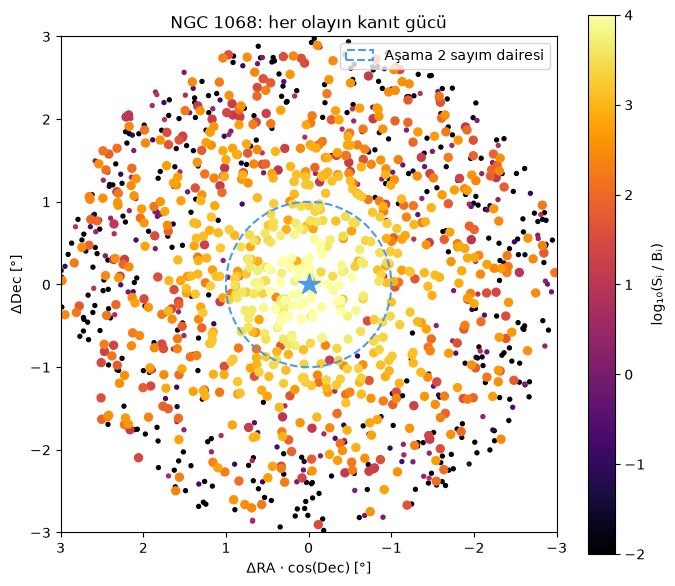

S/B > 100 olan olay sayısı: 635


In [3]:
ad = 'NGC 1068'
ra_k, dec_k = ps.KAYNAKLAR[ad]
psi = ps.acisal_uzaklik(ev['ra'].values, ev['dec'].values, ra_k, dec_k)
yakin = ev[psi < 3].copy()
psi_y = psi[psi < 3]
yakin['SB'] = ps.sinyal_pdf(psi_y, yakin['angErr'].values) / B(yakin['dec'].values)

fig, ax = plt.subplots(figsize=(8, 7))
x = (yakin['ra'] - ra_k) * np.cos(np.radians(dec_k))
y = yakin['dec'] - dec_k
sira = np.argsort(yakin['SB'].values)          # güçlü olaylar üstte çizilsin
sc = ax.scatter(x.values[sira], y.values[sira], c=np.log10(yakin['SB'].values[sira] + 1e-3),
                s=8 + 25 * (yakin['SB'].values[sira] > 10), cmap='inferno', vmin=-2, vmax=4)
fig.colorbar(sc, label='log₁₀(Sᵢ / Bᵢ)')
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color='#4c9be8', lw=1.5, ls='--',
                        label='Aşama 2 sayım dairesi'))
ax.plot(0, 0, '*', color='#4c9be8', ms=16)
ax.set_xlim(3, -3); ax.set_ylim(-3, 3); ax.set_aspect('equal')
ax.set_xlabel('ΔRA · cos(Dec) [°]'); ax.set_ylabel('ΔDec [°]')
ax.set_title(f'{ad}: her olayın kanıt gücü'); ax.legend(loc='upper right')
plt.savefig(RESULTS / 'asama3_sb_ngc1068.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"S/B > 100 olan olay sayısı: {np.sum(yakin['SB'] > 100)}")

## 3. Yöntem çalışıyor mu? Enjeksiyon testi

Gerçek veriye geçmeden önce yöntemi test ediyoruz: bilinen sayıda **sahte** sinyal olayı ekleyip likelihood'un bunları bulup bulamadığına bakıyoruz. Bulduğu $\hat n_s$ eklediğimiz sayıya yakın çıkmalı. Bilimde buna **closure test** denir: cevabını bildiğin bir soruyu çözemiyorsan, cevabını bilmediğin soruya verdiğin cevaba güvenemezsin.

Sahte olayları kuzey gökyüzünde boş bir noktaya koyuyoruz ki gerçek bir kaynakla karışmasın.

**Önemli bir ders:** Sahte olayların hepsine aynı belirsizliği (ör. 0.5°) verirsek likelihood $n_s$'i sistematik olarak ~%25 **düşük** buluyor. Sebebi: model, sinyal ve arka plan olaylarının belirsizliklerinin benzer dağıldığını varsayıyor. Sahte sinyal bu varsayımı bozarsa sonuç kayıyor. O yüzden her sahte olayın belirsizliğini gerçek verinin angErr dağılımından çekiyoruz ve konumunu o belirsizlik kadar saçıyoruz. Simülasyon gerçekçi değilse test de yanıltıcı olur. (Aşama 5'te dedektör tepki dosyalarıyla bunu daha da gerçekçi yapacağız.)

In [4]:
rng = np.random.default_rng(7)
ra_t, dec_t = 180.0, 30.0          # test noktası

def sahte_kaynak(n, ra0, dec0):
    sig = rng.choice(ev['angErr'].values, n)       # gerçekçi belirsizlikler
    return pd.DataFrame(dict(
        ra=ra0 + rng.normal(0, sig) / np.cos(np.radians(dec0)),
        dec=dec0 + rng.normal(0, sig),
        angErr=sig))

satirlar = []
for n_enj in [0, 10, 20, 40, 80]:
    bulunan = []
    for _ in range(5):                               # her sayı için 5 tekrar
        veri = pd.concat([ev, sahte_kaynak(n_enj, ra_t, dec_t)], ignore_index=True)
        bulunan.append(ps.NoktaKaynakLikelihood(veri, B, ra_t, dec_t).fit())
    bulunan = np.array(bulunan)
    satirlar.append(dict(eklenen=n_enj,
                         bulunan_ns_ort=round(bulunan[:, 0].mean(), 1),
                         TS_ort=round(bulunan[:, 1].mean(), 1)))
pd.DataFrame(satirlar)

,eklenen,bulunan_ns_ort,TS_ort
0,0,0.0,0.0
1,10,11.8,1.6
2,20,29.5,8.6
3,40,58.4,29.2
4,80,99.5,70.5


## 4. Dört kaynak için fit

Her kaynak için $\log\mathcal{L}(n_s)$'i maksimize ediyoruz ve test istatistiğini hesaplıyoruz:

$$TS = 2\ln\frac{\mathcal{L}(\hat n_s)}{\mathcal{L}(0)}$$

TS büyükse "kaynak var" hipotezi veriyi "sadece arka plan"dan çok daha iyi açıklıyor.

In [5]:
modeller, fitler = {}, []
for ad, (ra_k, dec_k) in ps.KAYNAKLAR.items():
    L = ps.NoktaKaynakLikelihood(ev, B, ra_k, dec_k)
    ns, ts = L.fit()
    modeller[ad] = L
    fitler.append(dict(kaynak=ad, ns=round(ns, 1), TS=round(ts, 2)))
pd.DataFrame(fitler)

,kaynak,ns,TS
0,TXS 0506+056,16.4,1.88
1,NGC 1068,50.7,17.40
2,PKS 1424+240,38.9,8.91
3,GB6 J1542+6129,29.7,9.30


## 5. $n_s$ ne kadar kesin? Likelihood profili

$-2\Delta\ln\mathcal{L}$ eğrisinin tabanı en iyi $n_s$'i, eğrinin 1 birim yükseldiği noktalar da **1σ belirsizlik aralığını** veriyor (yine Wilks teoreminin bir sonucu). Eğri ne kadar darsa ölçüm o kadar kesin.

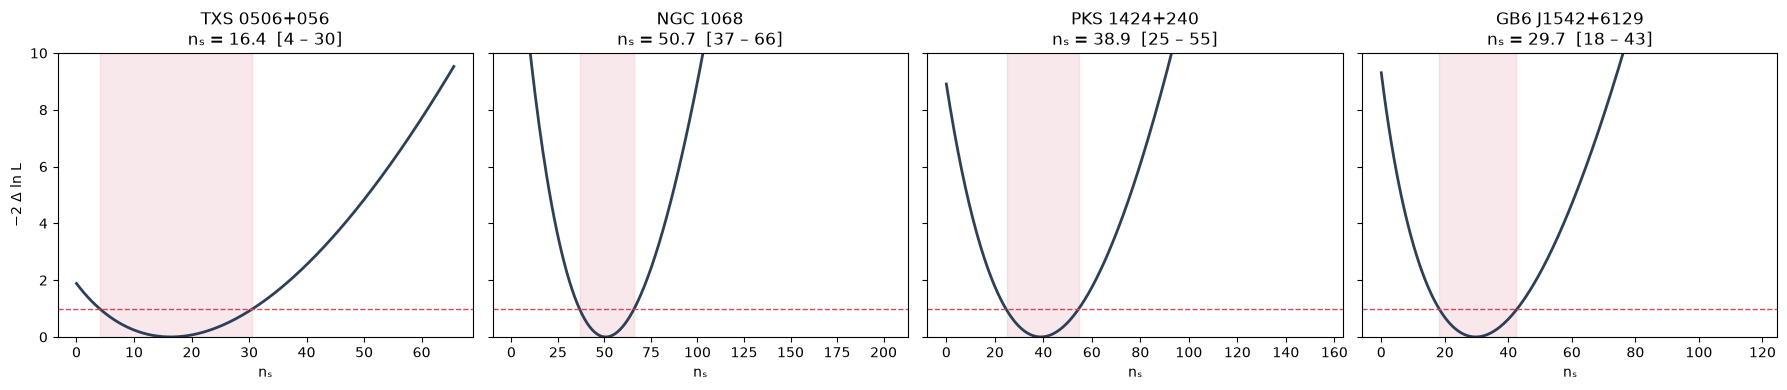

In [6]:
fig, axs = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, f in zip(axs, fitler):
    L = modeller[f['kaynak']]
    ns_d = np.linspace(0, max(4 * f['ns'], 20), 300)
    prof = L.profil(ns_d)
    ax.plot(ns_d, prof, color='#2e4057', lw=2)
    ax.axhline(1, color='#d1495b', ls='--', lw=1)
    icinde = ns_d[prof <= 1]
    ax.axvspan(icinde.min(), icinde.max(), color='#d1495b', alpha=0.12)
    f['ns_1sigma'] = f"{icinde.min():.0f} – {icinde.max():.0f}"
    ax.set_title(f"{f['kaynak']}\nnₛ = {f['ns']}  [{f['ns_1sigma']}]")
    ax.set_xlabel('nₛ'); ax.set_ylim(0, 10)
axs[0].set_ylabel('−2 Δ ln L')
plt.tight_layout()
plt.savefig(RESULTS / 'asama3_profil.png', dpi=150)
plt.show()

## 6. Anlamlılık: Arka plan TS dağılımı

Aşama 2'deki mantığın aynısı, ama sayım yerine TS ile: RA'ları karıştırıp sahte gökyüzlerinde TS'yi yeniden hesaplıyoruz.

İki beklenti:
- Denemelerin yaklaşık **yarısında TS = 0** çıkmalı. Arka plan rastgele dalgalandığında yarı yarıya "eksik" çıkar, o zaman en iyi $n_s$ = 0 olur (negatif kaynak fiziksel değil).
- Kalan yarı **χ² dağılımına (1 serbestlik derecesi)** uymalı. Bu, istatistiğin en önemli sonuçlarından biri olan **Wilks teoremi**.

Wilks'in faydası: Monte Carlo 10.000 denemeyle ~3.7σ'nın üstünü ölçemiyordu (Aşama 2'deki NGC 1068 sorunu). Dağılımın χ²'ye uyduğunu gösterirsek kuyruğu formülle hesaplayabiliriz.

⏱️ Kaynak başına 10.000 deneme birkaç dakika sürüyor. Sonuçlar `results/` klasörüne kaydediliyor, notebook'u yeniden çalıştırınca baştan hesaplanmıyor.

In [7]:
N_DENEME = 10_000
rng = np.random.default_rng(42)
ts_arka = {}
for ad, L in modeller.items():
    dosya = RESULTS / f"ts_arka_{ad.replace(' ', '_').replace('+', 'p')}.npy"
    if dosya.exists():
        ts_arka[ad] = np.load(dosya)
    else:
        print(f"{ad}: {N_DENEME:,} deneme...", flush=True)
        ts_arka[ad] = L.arka_plan_denemeleri(N_DENEME, rng)
        np.save(dosya, ts_arka[ad])
    print(f"{ad}: TS=0 oranı = {np.mean(ts_arka[ad] == 0):.2f}")

TXS 0506+056: 10,000 deneme...
TXS 0506+056: TS=0 oranı = 0.52
NGC 1068: 10,000 deneme...
NGC 1068: TS=0 oranı = 0.53
PKS 1424+240: 10,000 deneme...
PKS 1424+240: TS=0 oranı = 0.52
GB6 J1542+6129: 10,000 deneme...
GB6 J1542+6129: TS=0 oranı = 0.55


In [8]:
for f in fitler:
    ts_a = ts_arka[f['kaynak']]
    p_mc, p_w = ps.p_degeri(f['TS'], ts_a)
    f.update(p_MC=p_mc, sigma_MC=round(ps.sigma(p_mc), 2),
             p_Wilks=p_w, sigma_Wilks=round(ps.sigma(p_w), 2))

sonuc = pd.DataFrame(fitler)
# Aşama 2 ile karşılaştır
asama2 = RESULTS / 'asama2_sayim.csv'
if asama2.exists():
    sonuc = sonuc.merge(pd.read_csv(asama2)[['kaynak', 'sigma']].rename(
        columns={'sigma': 'sigma_sayim'}), on='kaynak')
sonuc.to_csv(RESULTS / 'asama3_likelihood.csv', index=False)
sonuc

,kaynak,ns,TS,ns_1sigma,p_MC,sigma_MC,p_Wilks,sigma_Wilks,sigma_sayim
0,TXS 0506+056,16.4,1.88,4 – 30,0.077192,1.42,0.082237,1.39,0.80
1,NGC 1068,50.7,17.40,37 – 66,0.000200,3.54,0.000014,4.18,3.54
2,PKS 1424+240,38.9,8.91,25 – 55,0.001700,2.93,0.001374,2.99,1.65
3,GB6 J1542+6129,29.7,9.30,18 – 43,0.001400,2.99,0.001036,3.08,0.98


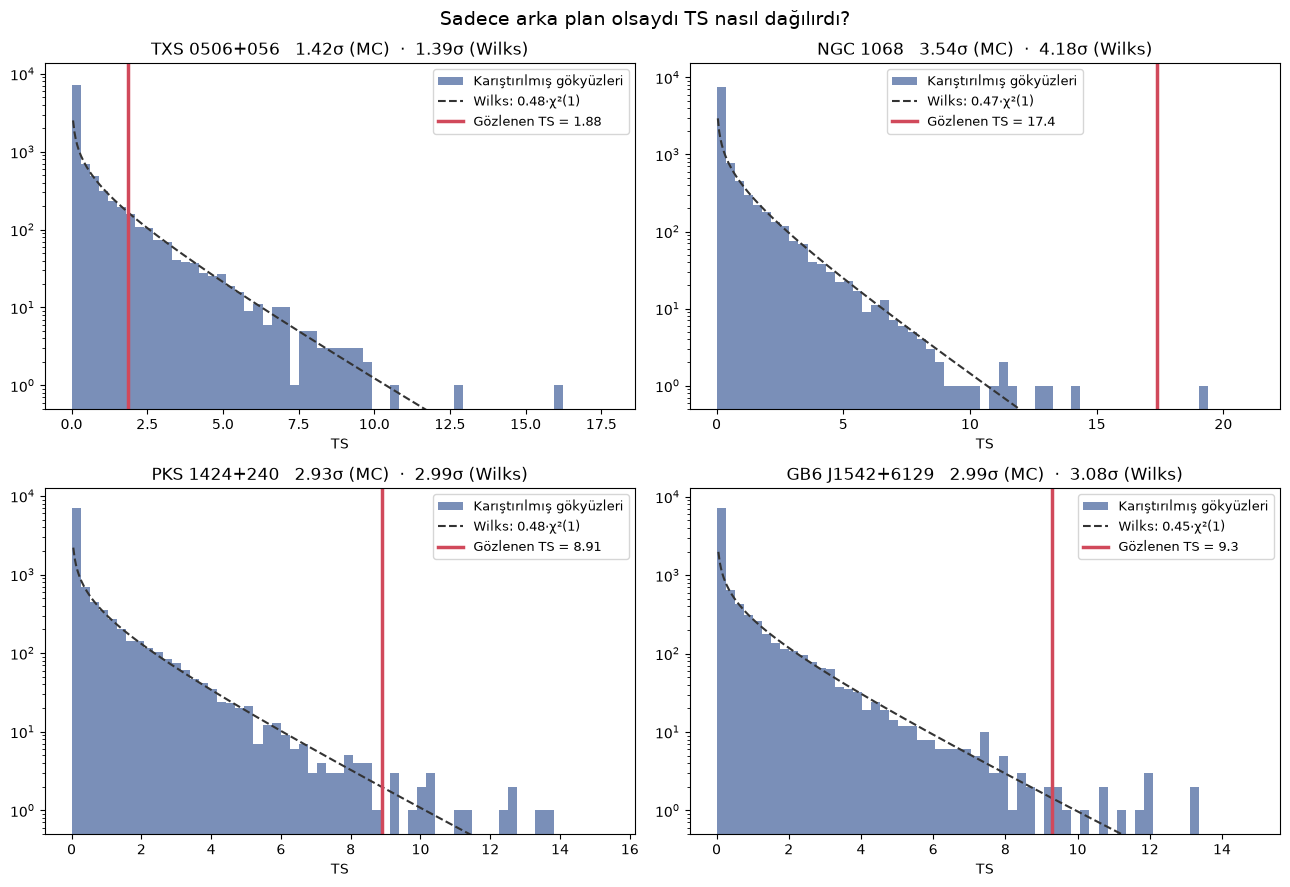

In [9]:
fig, axs = plt.subplots(2, 2, figsize=(13, 9))
for ax, f in zip(axs.flat, fitler):
    ts_a = ts_arka[f['kaynak']]
    ust = max(ts_a.max(), f['TS']) * 1.05 + 1
    kutu = np.linspace(0, ust, 60)
    ax.hist(ts_a, bins=kutu, color='#7a8fb8', label='Karıştırılmış gökyüzleri')
    eta = np.mean(ts_a > 0)
    x = np.linspace(0.05, ust, 400)
    ax.plot(x, eta * stats.chi2.pdf(x, 1) * len(ts_a) * (kutu[1] - kutu[0]),
            color='#333', ls='--', label=f'Wilks: {eta:.2f}·χ²(1)')
    ax.axvline(f['TS'], color='#d1495b', lw=2.5, label=f"Gözlenen TS = {f['TS']}")
    ax.set_yscale('log'); ax.set_ylim(0.5, None)
    ax.set_title(f"{f['kaynak']}   {f['sigma_MC']}σ (MC)  ·  {f['sigma_Wilks']}σ (Wilks)")
    ax.set_xlabel('TS'); ax.legend(fontsize=9)
fig.suptitle('Sadece arka plan olsaydı TS nasıl dağılırdı?', fontsize=14)
plt.tight_layout()
plt.savefig(RESULTS / 'asama4_ts_dagilimi.png', dpi=150)
plt.show()

## Yorumlarken

- **Sayım vs. likelihood:** Son tablodaki `sigma_sayim` ve `sigma_Wilks`'i karşılaştır. Likelihood açısal belirsizliği kullandığı için genelde daha güçlü; ama tek bir kaynakta daha düşük çıkması da mümkün (daire içindeki olayların çoğu belirsiz olaylarsa).
- **Wilks eğrisi histograma oturuyor mu?** Oturuyorsa Monte Carlo'nun ulaşamadığı kuyrukta Wilks sonucuna güvenebiliriz. Oturmuyorsa bu da bir bulgudur.
- **Hâlâ bir doğrulama:** Kaynakları IceCube'un sonucuna bakarak seçtik. Gerçek bir keşif iddiası için bütün gökyüzünü önyargısız taramak (Aşama 7) ve "her yere baktık" düzeltmesini yapmak gerekiyor.
- **Eksik olan:** Enerji bilgisi. Astrofiziksel nötrinolar atmosferik olanlardan daha yüksek enerjili; IceCube bunu da likelihood'a katıyor (Aşama 9).